## **Subtask 1: train an image segmenter**

Loads only segmented images for training

In [1]:
import numpy as np
from glob import glob
from PIL import Image
import tensorflow as tf
from tensorflow import keras as K
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
import os

In [2]:
IMG_DIR = "data/images/segmented"
MASK_DIR = "data/masks"

def load_segmented_split(img_dir=IMG_DIR, mask_dir=MASK_DIR, seed=42):
    # carica e ordina percorsi immagine/mask (stessi ID)
    img_paths  = sorted(glob(os.path.join(img_dir,  "*.png")))
    mask_paths = sorted(glob(os.path.join(mask_dir, "*.png")))
    print(img_paths[1], mask_paths[1]) # check print
    images = [np.array(Image.open(p).convert("RGB"), dtype=np.float32) for p in img_paths]

    # --- MASCHERE: binarizza a {0,1} e aggiungi canale (H,W,1) ---
    masks = [
        (np.array(Image.open(p).convert("L"), dtype=np.uint8) > 127).astype(np.float32)[..., None]
        for p in mask_paths
    ]

    X = np.stack(images, axis=0)   # (N,H,W,3)
    Y = np.stack(masks,  axis=0)   # (N,H,W,1)
    print("Tot immagini:", X.shape[0], " | Tot maschere:", Y.shape[0])

    # split 7:1:2 → train (70%), temp (30%) poi val (10%) e test (20%)
    X_train, X_temp, Y_train, Y_temp = train_test_split(X, Y, test_size=0.30, random_state=seed, shuffle=True)

    # val = 1/3 di temp (10% tot), test = 2/3 (20% tot)
    X_val, X_test, Y_val, Y_test = train_test_split(X_temp, Y_temp, test_size=2/3, random_state=seed, shuffle=True)

    return {
        "train_images": X_train, "train_label": Y_train,
        "val_images":   X_val,   "val_label":   Y_val,
        "test_images":  X_test,  "test_label":  Y_test
    }

dataset = load_segmented_split()


data/images/segmented\1001.png data/masks\1001.png
Tot immagini: 600  | Tot maschere: 600


In [3]:
# check that everything is okay
for key in ["train_images", "train_label", "val_images", "val_label", "test_images", "test_label"]:
    print(f"{key:<12} -> {dataset[key].shape}")


train_images -> (420, 224, 224, 3)
train_label  -> (420, 224, 224, 1)
val_images   -> (60, 224, 224, 3)
val_label    -> (60, 224, 224, 1)
test_images  -> (120, 224, 224, 3)
test_label   -> (120, 224, 224, 1)


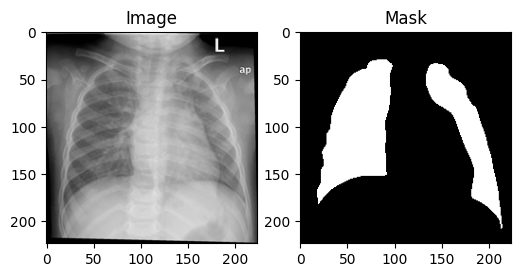

In [4]:
# An example of an image and its mask.
def show_image_mask():
    num_samples = dataset["train_images"].shape[0]
    index = np.random.choice(num_samples)
    image = dataset["train_images"][index]
    label = dataset["train_label"][index]

    fig, ax = plt.subplots(1, 2, figsize=(6, 3))
    ax[0].imshow(image/255)
    ax[0].set_title('Image')
    ax[1].imshow(label, cmap='gray')
    ax[1].set_title('Mask')
    plt.show()

show_image_mask()


##### Building U-NET

In [5]:
# PRIMO  building block
def double_conv_block(x, n_filters):
    """Implements blue arrows in the unet picture."""
    # Conv2D then ReLU activation
    x = K.layers.Conv2D(filters=n_filters, kernel_size=(3,3), padding="same", activation="relu")(x) # x_in → x_out
    # Conv2D then ReLU activation
    x = K.layers.Conv2D(filters=n_filters, kernel_size=(3,3), padding="same", activation="relu")(x) # x_out → x_final
    return x

# SECONDO  building block
def downsample_block(x, n_filters):
    """Implements red arrows in the unet picture."""
    x_res = double_conv_block(x, n_filters)
    x = K.layers.MaxPool2D(pool_size=(2,2))(x_res)
    x = K.layers.Dropout(0.5)(x)
    return x_res, x

# TERZO  building block
def upsample_block(x, x_res, n_filters):
    """Implements green arrows in the unet picture."""
    # upsample
    x = K.layers.Conv2DTranspose(filters=n_filters, kernel_size=(3,3), strides=(2,2), padding="same")(x)
    # create skip connection by concatenating the residual (gray arrow in the picture)
    x = K.layers.concatenate([x, x_res])
    # dropout
    x = K.layers.Dropout(0.5)(x)
    # Conv2D twice with ReLU activation
    x = double_conv_block(x, n_filters)
    return x

# QUARTO building block
def output_layer(x):
    """Implements turquoise arrow in the unet picture."""
    x = K.layers.Conv2D(filters=1, kernel_size=(1,1), padding="same", activation="sigmoid")(x)
    return x

In [6]:
def build_unet(n_filters=16):
    inputs = K.Input(shape=(224, 224, 3))
    x = K.layers.Rescaling(scale=1/255)(inputs) # rescaling layer

    f1 = n_filters
    f2 = n_filters * 2
    f3 = n_filters * 4
    f4 = n_filters * 8

    # ----- ENCODER -----
    # 1 - downsample
    enc_skip1, enc1 = downsample_block(x, f1)
    # 2 - downsample
    enc_skip2, enc2 = downsample_block(enc1, f2)
    # 3 - downsample
    enc_skip3, enc3 = downsample_block(enc2, f3)

    # ----- BOTTLENECK -----
    bottleneck = double_conv_block(enc3, f4)

    # ----- DECODER -----
    # 4 - upsample
    dec3 = upsample_block(bottleneck, enc_skip3, f3)
    # 5 - upsample
    dec2 = upsample_block(dec3, enc_skip2, f2)
    # 6 - upsample
    dec1 = upsample_block(dec2, enc_skip1, f1)

    # ----- OUTPUT -----
    outputs = output_layer(dec1) # segmented binary mask

    # unet model with Keras Functional API
    unet = K.Model(inputs, outputs, name="Unet")
    return unet

In [7]:
# Build model
model = build_unet()
model.summary()


Model: "Unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 224, 224,  │        448 │ rescaling[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 224, 224,  │      2,320 │ conv2d[0][0]      │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 112, 112,  │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 112, 112,  │          0 │ max_pooling2d[0]… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 112, 112,  │      4,640 │ dropout[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 112, 112,  │      9,248 │ conv2d_2[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 56, 56,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 56, 56,    │          0 │ max_pooling2d_1[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 56, 56,    │     18,496 │ dropout_1[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 56, 56,    │     36,928 │ conv2d_4[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 28, 28,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 28, 28,    │          0 │ max_pooling2d_2[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 28, 28,    │     73,856 │ dropout_2[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 28, 28,    │    147,584 │ conv2d_6[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 56, 56,    │     73,792 │ conv2d_7[0][0]  

 Total params: 535,793 (2.04 MB)

 Trainable params: 535,793 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

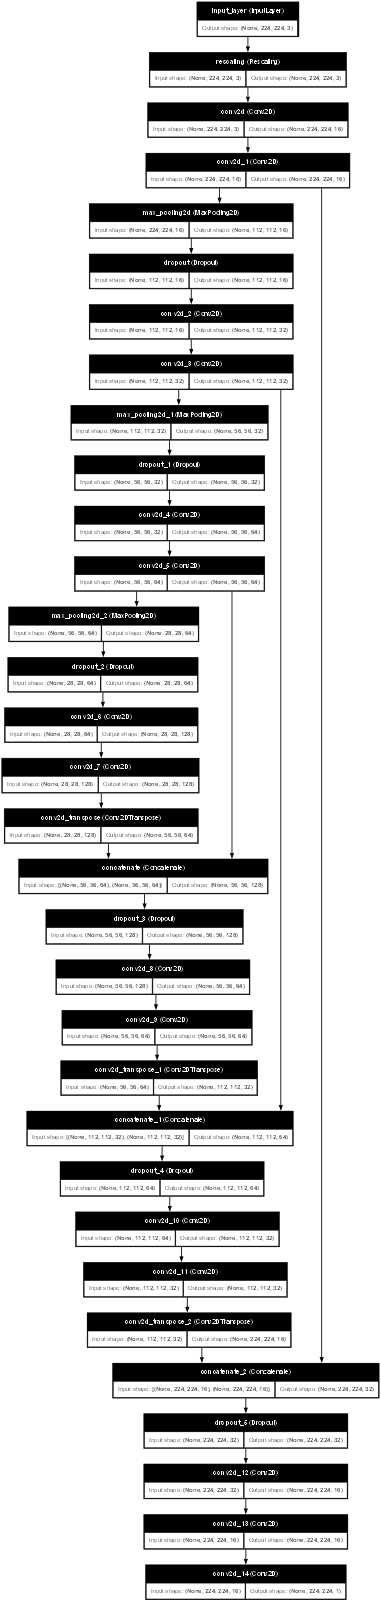

In [8]:
K.utils.plot_model(model, dpi=30, show_shapes=True, show_layer_names=True)

##### Metrics

In [9]:
import tensorflow as tf

def dice_loss(y_true, y_pred, smooth=1e-7):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    # Flatten each sample in the batch: [B, H, W, C] → [B, -1]
    y_true_flat = tf.reshape(y_true, [tf.shape(y_true)[0], -1])
    y_pred_flat = tf.reshape(y_pred, [tf.shape(y_pred)[0], -1])

    intersection = tf.reduce_sum(y_true_flat * y_pred_flat, axis=1)
    denominator = tf.reduce_sum(y_true_flat + y_pred_flat, axis=1)

    # add a small constant so the denominator is > 0
    dice_coeff = (2. * intersection + smooth) / (denominator + smooth)

    return 1. - tf.reduce_mean(dice_coeff)

def dice_bce_loss(alpha):
    def loss(y_true, y_pred):
        bce = K.losses.binary_crossentropy(y_true, y_pred)
        dice = dice_loss(y_true, y_pred)
        return alpha * bce + (1 - alpha) * dice
    return loss

##### U-Net training

In [10]:
# Graphic of the iou/epoch curves to check for overfitting and diagnose the training
def plot_metric(history, metric):
    train_metric = history[metric]
    val_metric = history[f"val_{metric}"]
    plt.plot(train_metric, label=f"Training {metric}")
    plt.plot(val_metric, label=f"Validation {metric}")
    plt.xlabel("Epoch")
    plt.ylabel(metric)
    plt.grid(True)
    plt.legend()

In [15]:
train_alpha_model_test = []
def train_model(alpha, model_build, n_filters, max_epoch=80):
    model = model_build(n_filters)
    model.compile(
        optimizer=K.optimizers.Adam(learning_rate=1e-3),
        loss=dice_bce_loss(alpha=alpha),
        metrics=[K.metrics.BinaryIoU(name="iou", threshold=0.5),"accuracy", "precision", "recall"]
    )

    # Save only the weights of the model achieving the highest validation IoU
    checkpoint_cb = K.callbacks.ModelCheckpoint(
        f"models/tmp_a{alpha:.1f}.weights.h5",
        monitor="val_iou",    # monitoring of iou on validation set
        mode="max",
        save_best_only=True,
        save_weights_only=True
    )

    # decreases the learning rate when performance stops improving
    reduce_cb = K.callbacks.ReduceLROnPlateau(
        monitor="val_iou",
        mode="max",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    )

    # stops training when the model no longer improves
    early_cb = K.callbacks.EarlyStopping(
        monitor="val_iou",
        mode="max",
        patience=20,
        restore_best_weights=True,
        verbose=1
    )

    # Train the model
    results = model.fit(
        dataset["train_images"],
        dataset["train_label"],
        epochs=max_epoch,
        batch_size=8,
        validation_data=(dataset["val_images"], dataset["val_label"]),
        callbacks=[checkpoint_cb, reduce_cb, early_cb],
        verbose=1
    )

    # to save the best version of each model variant (different filters, alphas and epochs)
    best_val_iou = float(np.max(results.history["val_iou"]))
    best_epoch   = int(np.argmax(results.history["val_iou"]))
    print(f"[α={alpha}] Best val IoU = {best_val_iou:.4f} in epoch {best_epoch}")
    plot_metric(results.history, "iou")

    train_alpha_model_test.append({
        "model": model.name,
        "alpha": alpha,
        "best_val_iou": best_val_iou,
        "weights_path": f"models/tmp_a{alpha:.1f}.weights.h5"
    })


In [22]:
# 3 variant of U-NET
filter_16 = 16 # normal
filter_8 = 8 # small
filter_32 = 32 # large

Epoch 1/80
53/53 ━━━━━━━━━━━━━━━━━━━━ 54s 888ms/step - accuracy: 0.7095 - iou: 0.4110 - loss: 0.6161 - precision: 0.2634 - recall: 0.1763 - val_accuracy: 0.8841 - val_iou: 0.7474 - val_loss: 0.2917 - val_precision: 0.7556 - val_recall: 0.8084 - learning_rate: 0.0010
Epoch 2/80
53/53 ━━━━━━━━━━━━━━━━━━━━ 49s 925ms/step - accuracy: 0.9076 - iou: 0.7882 - loss: 0.2375 - precision: 0.8298 - recall: 0.8069 - val_accuracy: 0.7427 - val_iou: 0.5723 - val_loss: 0.4463 - val_precision: 0.4985 - val_recall: 0.9408 - learning_rate: 0.0010
Epoch 3/80
53/53 ━━━━━━━━━━━━━━━━━━━━ 38s 718ms/step - accuracy: 0.9374 - iou: 0.8494 - loss: 0.1643 - precision: 0.8780 - recall: 0.8737 - val_accuracy: 0.9188 - val_iou: 0.8212 - val_loss: 0.1830 - val_precision: 0.7809 - val_recall: 0.9491 - learning_rate: 0.0010
Epoch 4/80
53/53 ━━━━━━━━━━━━━━━━━━━━ 39s 739ms/step - accuracy: 0.9548 - iou: 0.8895 - loss: 0.1174 - precision: 0.9131 - recall: 0.9107 - val_accuracy: 0.9374 - val_iou: 0.8558 - val_loss: 0.1497 -

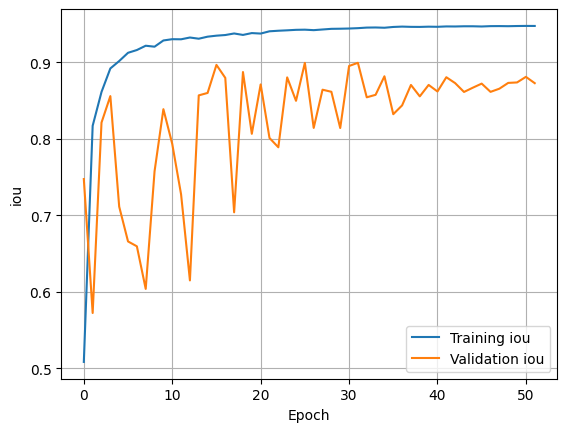

In [16]:
# Normal U-NET (16, 32, 64, 128): 0.3 alpha | 80 epoch
train_model(0.3, build_unet, filter_16, 80)

Epoch 1/80
53/53 ━━━━━━━━━━━━━━━━━━━━ 75s 1s/step - accuracy: 0.6709 - iou: 0.3713 - loss: 0.6432 - precision: 0.2794 - recall: 0.1663 - val_accuracy: 0.7742 - val_iou: 0.4599 - val_loss: 0.5559 - val_precision: 0.7838 - val_recall: 0.1623 - learning_rate: 0.0010
Epoch 2/80
53/53 ━━━━━━━━━━━━━━━━━━━━ 75s 1s/step - accuracy: 0.8119 - iou: 0.5449 - loss: 0.4953 - precision: 0.8792 - recall: 0.3062 - val_accuracy: 0.7301 - val_iou: 0.5582 - val_loss: 0.4658 - val_precision: 0.4859 - val_recall: 0.9436 - learning_rate: 0.0010
Epoch 3/80
53/53 ━━━━━━━━━━━━━━━━━━━━ 67s 1s/step - accuracy: 0.9103 - iou: 0.7871 - loss: 0.2615 - precision: 0.8511 - recall: 0.7796 - val_accuracy: 0.7525 - val_iou: 0.5854 - val_loss: 0.6031 - val_precision: 0.5086 - val_recall: 0.9654 - learning_rate: 0.0010
Epoch 4/80
53/53 ━━━━━━━━━━━━━━━━━━━━ 67s 1s/step - accuracy: 0.9351 - iou: 0.8426 - loss: 0.1793 - precision: 0.9027 - recall: 0.8375 - val_accuracy: 0.7665 - val_iou: 0.6032 - val_loss: 0.5190 - val_precisi

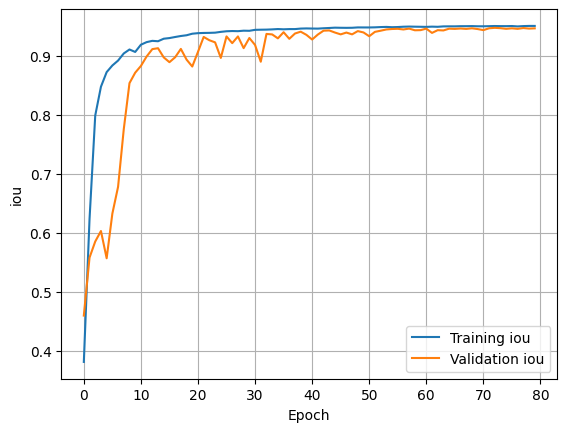

In [17]:
# Normal U-NET (16, 32, 64, 128): 0.5 alpha | 80 epoch
train_model(0.5, build_unet, filter_16, 80)

Epoch 1/80
53/53 ━━━━━━━━━━━━━━━━━━━━ 40s 629ms/step - accuracy: 0.6379 - iou: 0.3613 - loss: 0.6416 - precision: 0.2692 - recall: 0.2289 - val_accuracy: 0.7442 - val_iou: 0.3721 - val_loss: 0.5218 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/80
53/53 ━━━━━━━━━━━━━━━━━━━━ 41s 784ms/step - accuracy: 0.7718 - iou: 0.4449 - loss: 0.4760 - precision: 0.6542 - recall: 0.1292 - val_accuracy: 0.6928 - val_iou: 0.5203 - val_loss: 0.5256 - val_precision: 0.4540 - val_recall: 0.9901 - learning_rate: 0.0010
Epoch 3/80
53/53 ━━━━━━━━━━━━━━━━━━━━ 41s 781ms/step - accuracy: 0.9276 - iou: 0.8238 - loss: 0.2106 - precision: 0.8946 - recall: 0.8095 - val_accuracy: 0.9100 - val_iou: 0.8042 - val_loss: 0.2629 - val_precision: 0.7653 - val_recall: 0.9352 - learning_rate: 0.0010
Epoch 4/80
53/53 ━━━━━━━━━━━━━━━━━━━━ 40s 749ms/step - accuracy: 0.9322 - iou: 0.8351 - loss: 0.1910 - precision: 0.9151 - recall: 0.8131 - val_accuracy: 0.7718 - val_iou: 0.6098 - val_loss: 

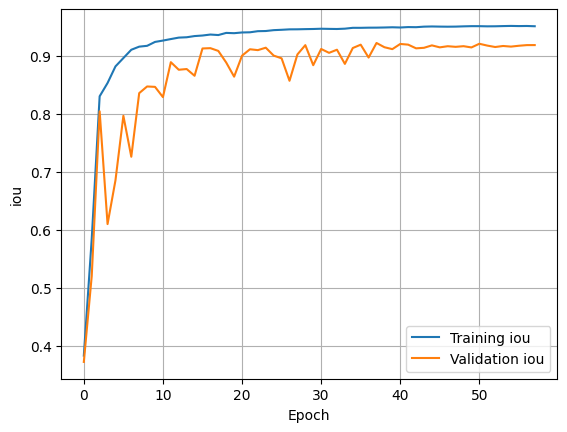

In [18]:
# Normal U-NET (16, 32, 64, 128): 0.7 alpha | 80 epoch
train_model(0.7, build_unet, filter_16, 80)

##### Check result on validation and save best model

In [19]:
best = max(train_alpha_model_test, key=lambda d: d["best_val_iou"])
print("α =", best["alpha"], " | val IoU =", best["best_val_iou"])

best_model = build_unet(filter_16)
best_model.load_weights(best["weights_path"])
best_model.save("models/best_model_tmp.keras")
print("Salvato miglior modello intero:", "models/best_model_tmp.keras")


α = 0.5  | val IoU = 0.9476748704910278
Salvato miglior modello intero: models/best_model_tmp.keras


##### Another test with a small (filter_8) and a large (filter_32) U-Net, using respectively 120 and 45 epochs and alpha=0.5.


Epoch 1/120
53/53 ━━━━━━━━━━━━━━━━━━━━ 20s 237ms/step - accuracy: 0.6757 - iou: 0.3750 - loss: 0.6524 - precision: 0.2724 - recall: 0.1531 - val_accuracy: 0.7442 - val_iou: 0.3721 - val_loss: 0.5865 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/120
53/53 ━━━━━━━━━━━━━━━━━━━━ 16s 304ms/step - accuracy: 0.7594 - iou: 0.4187 - loss: 0.5197 - precision: 0.6330 - recall: 0.0871 - val_accuracy: 0.5615 - val_iou: 0.3894 - val_loss: 0.5662 - val_precision: 0.3676 - val_recall: 0.9916 - learning_rate: 0.0010
Epoch 3/120
53/53 ━━━━━━━━━━━━━━━━━━━━ 25s 484ms/step - accuracy: 0.9017 - iou: 0.7719 - loss: 0.3800 - precision: 0.8333 - recall: 0.7689 - val_accuracy: 0.6456 - val_iou: 0.4709 - val_loss: 1.1006 - val_precision: 0.4182 - val_recall: 0.9855 - learning_rate: 0.0010
Epoch 4/120
53/53 ━━━━━━━━━━━━━━━━━━━━ 30s 262ms/step - accuracy: 0.9235 - iou: 0.8184 - loss: 0.2111 - precision: 0.8753 - recall: 0.8202 - val_accuracy: 0.6832 - val_iou: 0.5095 - val_lo

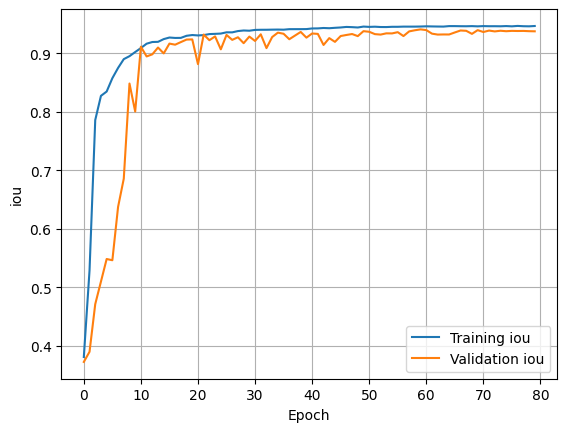

In [21]:
# Small U-NET: best alpha | 120 epoch
train_model(0.5, build_unet, filter_8, 120)


Epoch 1/45
53/53 ━━━━━━━━━━━━━━━━━━━━ 128s 2s/step - accuracy: 0.6821 - iou: 0.3722 - loss: 0.6718 - precision: 0.2749 - recall: 0.1394 - val_accuracy: 0.7690 - val_iou: 0.4397 - val_loss: 0.5260 - val_precision: 0.8364 - val_recall: 0.1205 - learning_rate: 0.0010
Epoch 2/45
53/53 ━━━━━━━━━━━━━━━━━━━━ 127s 2s/step - accuracy: 0.7386 - iou: 0.4115 - loss: 0.6191 - precision: 0.4397 - recall: 0.1153 - val_accuracy: 0.8418 - val_iou: 0.6131 - val_loss: 0.5266 - val_precision: 0.9191 - val_recall: 0.4182 - learning_rate: 0.0010
Epoch 3/45
53/53 ━━━━━━━━━━━━━━━━━━━━ 128s 2s/step - accuracy: 0.8411 - iou: 0.6256 - loss: 0.4934 - precision: 0.7971 - recall: 0.4886 - val_accuracy: 0.7449 - val_iou: 0.5769 - val_loss: 0.9355 - val_precision: 0.5008 - val_recall: 0.9696 - learning_rate: 0.0010
Epoch 4/45
53/53 ━━━━━━━━━━━━━━━━━━━━ 125s 2s/step - accuracy: 0.9261 - iou: 0.8242 - loss: 0.2010 - precision: 0.8743 - recall: 0.8308 - val_accuracy: 0.9168 - val_iou: 0.8166 - val_loss: 0.2116 - val_pre

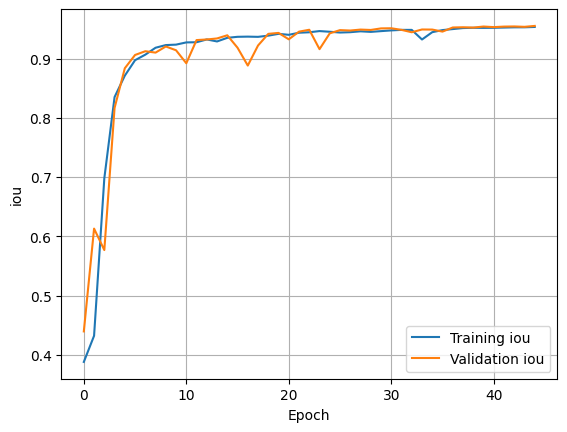

In [23]:
# Big U-NET: best alpha | 45 epoch
train_model(0.5, build_unet, filter_32, 45)

In [24]:
train_alpha_model_test

[{'model': 'Unet',
  'alpha': 0.3,
  'best_val_iou': 0.8993217945098877,
  'weights_path': 'models/tmp_a0.3.weights.h5'},
 {'model': 'Unet',
  'alpha': 0.5,
  'best_val_iou': 0.9476748704910278,
  'weights_path': 'models/tmp_a0.5.weights.h5'},
 {'model': 'Unet',
  'alpha': 0.7,
  'best_val_iou': 0.9221090078353882,
  'weights_path': 'models/tmp_a0.7.weights.h5'},
 {'model': 'Unet',
  'alpha': 0.5,
  'best_val_iou': 0.9408169984817505,
  'weights_path': 'models/tmp_a0.5.weights.h5'},
 {'model': 'Unet',
  'alpha': 0.5,
  'best_val_iou': 0.9549825191497803,
  'weights_path': 'models/tmp_a0.5.weights.h5'}]

In [25]:
# select the best on validation
best = max(train_alpha_model_test, key=lambda d: d["best_val_iou"])
print("α =", best["alpha"], " | val IoU =", best["best_val_iou"])

α = 0.5  | val IoU = 0.9549825191497803


In [26]:
# best is on filter_32
best_model = build_unet(filter_32)
best_model.load_weights(best["weights_path"])
best_model.save("models/best_model.keras")
print("Salvato miglior modello intero:", "models/best_model.keras")

Salvato miglior modello intero: models/best_model.keras


##### Predicting test img

In [27]:
from keras.src.metrics import IoU
from keras import models
model = models.load_model(
    "models/best_model.keras",
    custom_objects={"IoU": IoU, "dice_bce_loss": dice_bce_loss}
)

model.compile(
    optimizer=K.optimizers.Adam(1e-3),
    loss=dice_bce_loss(alpha=0.5),
    metrics=[K.metrics.BinaryIoU(name="iou", threshold=0.5), "precision", "recall"]
)

test_results = model.evaluate(dataset["test_images"], dataset["test_label"], verbose=1)
for n, v in zip(model.metrics_names, test_results):
    print(f"TEST {n}: {v:.4f}")


4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - iou: 0.9494 - loss: 0.0536 - precision: 0.9730 - recall: 0.9470
TEST loss: 0.0539
TEST compile_metrics: 0.9495


see image result

In [28]:
predictions = model.predict(dataset["test_images"])

4/4 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step


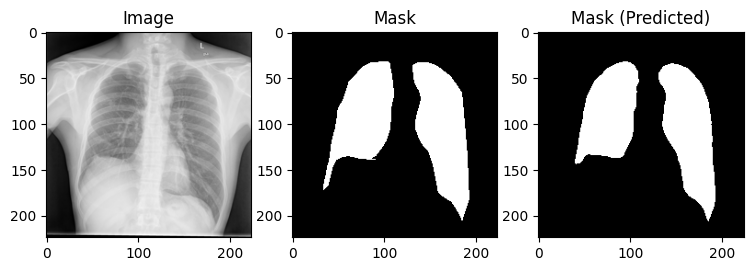

In [50]:
def show_image_mask_prediction(images, masks, predictions, threshold=0.5):
    """Compares predicted and ground truth masks on a random test image."""
    index = np.random.choice(images.shape[0])
    image = images[index]
    mask = masks[index]
    mask_p = (predictions[index].squeeze() > threshold).squeeze()  # 128x128

    fig, ax = plt.subplots(1, 3, figsize=(9, 3))
    ax[0].imshow(image/255)
    ax[0].set_title('Image')
    ax[1].imshow(mask, cmap='gray')
    ax[1].set_title('Mask')
    ax[2].imshow(mask_p, cmap='gray')
    ax[2].set_title('Mask (Predicted)')
    plt.show()

show_image_mask_prediction(dataset["test_images"], dataset["test_label"], predictions, threshold=0.9)

***
## **Subtask 2 - segment the images**

Loads the 99 unsegmented images

In [42]:
import os
import numpy as np
from PIL import Image

UNSEG_IMG_DIR = "data/images/unsegmented"
IMG_SHAPE = (224, 224)

def load_unsegmented_images(img_dir):
    img_paths = sorted([
        os.path.join(img_dir, f)
        for f in os.listdir(img_dir)
        if f.endswith(".png")
    ])

    images = []
    for p in img_paths:
        img = Image.open(p).convert("RGB").resize(IMG_SHAPE)
        images.append(np.array(img, dtype=np.float32))

    X_unseg = np.stack(images, axis=0)  # (N,H,W,3)
    print("Unsegmented images:", X_unseg.shape)
    return X_unseg, img_paths

X_unseg, unseg_paths = load_unsegmented_images(UNSEG_IMG_DIR)


Unsegmented images: (99, 224, 224, 3)


Uses the trained model to predict the missing lung masks

In [43]:
# Predict maschere polmonari
pred_masks = best_model.predict(X_unseg, verbose=1)

# Binarizzazione
pred_masks_bin = (pred_masks > 0.5).astype(np.float32)

print(pred_masks_bin.shape)  # (N,224,224,1)


4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step
(99, 224, 224, 1)


In [44]:
# applies the predicted masks to obtain segmented CXRs
segmented_unseg_images = X_unseg * pred_masks_bin

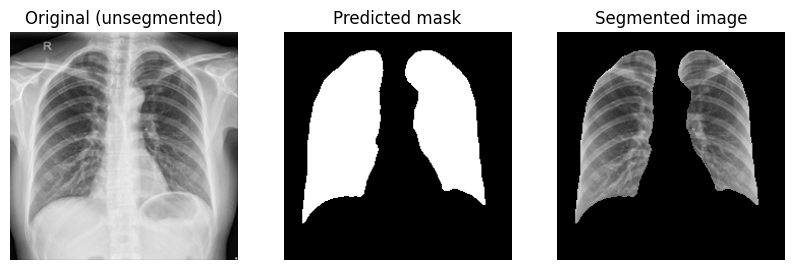

In [57]:
import matplotlib.pyplot as plt
import random

def show_unsegmented_result(X, masks, segmented):
    i = random.randint(0, X.shape[0] - 1)

    fig, ax = plt.subplots(1, 3, figsize=(10, 4))
    ax[0].imshow(X[i] / 255)
    ax[0].set_title("Original (unsegmented)")

    ax[1].imshow(masks[i].squeeze(), cmap="gray")
    ax[1].set_title("Predicted mask")

    ax[2].imshow(segmented[i] / 255)
    ax[2].set_title("Segmented image")

    for a in ax:
        a.axis("off")
    plt.show()

show_unsegmented_result(X_unseg, pred_masks_bin, segmented_unseg_images)


Saves the predicted masks

In [46]:
import os

MASK_PRED_DIR = "data/masks_predict"
os.makedirs(MASK_PRED_DIR,  exist_ok=True)


In [47]:
from PIL import Image
import numpy as np

for mask, img_path in zip(pred_masks_bin, unseg_paths):
    # Rimuove il canale singleton (H, W, 1) → (H, W)
    mask_2d = mask.squeeze()

    # Converte da {0,1} a {0,255}
    mask_uint8 = (mask_2d * 255).astype(np.uint8)

    # Nome file coerente con l’immagine originale
    filename = os.path.basename(img_path)
    save_path = os.path.join(MASK_PRED_DIR, filename)

    # Salva PNG
    Image.fromarray(mask_uint8).save(save_path)

print(f"Maschere predette salvate in: {MASK_PRED_DIR}")


Maschere predette salvate in: data/masks_predict


Save 699 CXR segmented img with correct ID

In [64]:
IMG_SEG_DIR   = "data/images/segmented"
MASK_DIR  = "data/masks"

IMG_UNSEG_DIR = "data/images/unsegmented"
MASK_PRED_DIR = "data/masks_predict"

OUT_DIR = "data/images/segmented_all"
os.makedirs(OUT_DIR, exist_ok=True)

def load_img(path):
    return np.array(Image.open(path).convert("RGB"), dtype=np.float32)

def load_mask(path):
    m = Image.open(path).convert("L")
    return (np.array(m, dtype=np.uint8) > 127).astype(np.float32)[..., None]

segmented_dict = {}

# --- IMMAGINI CON MASCHERA ORIGINALE ---
for fname in os.listdir(IMG_SEG_DIR):
    if not fname.endswith(".png"):
        continue
    img_id = int(os.path.splitext(fname)[0])
    img_path  = os.path.join(IMG_SEG_DIR, fname)
    mask_path = os.path.join(MASK_DIR, fname)
    img  = load_img(img_path)
    mask = load_mask(mask_path)
    segmented_dict[img_id] = img * mask

# --- IMMAGINI CON MASCHERA PREDETTA ---
for fname in os.listdir(IMG_UNSEG_DIR):
    if not fname.endswith(".png"):
        continue
    img_id = int(os.path.splitext(fname)[0])
    img_path  = os.path.join(IMG_UNSEG_DIR, fname)
    mask_path = os.path.join(MASK_PRED_DIR, fname)
    img  = load_img(img_path)
    mask = load_mask(mask_path)
    segmented_dict[img_id] = img * mask

# --- SAVE SORTED SEGMENTED IMG BY ID ---
for img_id in sorted(segmented_dict.keys()):
    img = np.clip(segmented_dict[img_id], 0, 255).astype(np.uint8)
    save_path = os.path.join(OUT_DIR, f"{img_id}.png")
    Image.fromarray(img).save(save_path)

print(f"Immagini segmentate salvate in: {OUT_DIR}")
print("Totale immagini:", len(segmented_dict))


Immagini segmentate salvate in: data/images/segmented_all
Totale immagini: 699
